In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import mahalanobis
from sklearn.neighbors import NearestNeighbors

In [3]:
gdata = pd.read_csv('/content/drive/MyDrive/Data_Mining_datasets/Lab9Datasets/G-data.csv', header=None)
gdata.columns = ['x', 'y']

compound = pd.read_csv('/content/drive/MyDrive/Data_Mining_datasets/Lab9Datasets/compound.txt', header=None,
                           delimiter='\t').iloc[:, :2]
compound.columns = ['x', 'y']

flame = pd.read_csv('/content/drive/MyDrive/Data_Mining_datasets/Lab9Datasets/flame.txt', header=None,
                           delimiter='\t').iloc[:, :2]
flame.columns = ['x', 'y']

pathbased = pd.read_csv('/content/drive/MyDrive/Data_Mining_datasets/Lab9Datasets/pathbased.txt', header=None,
                           delimiter='\t').iloc[:, :2]
pathbased.columns = ['x', 'y']

## Part I

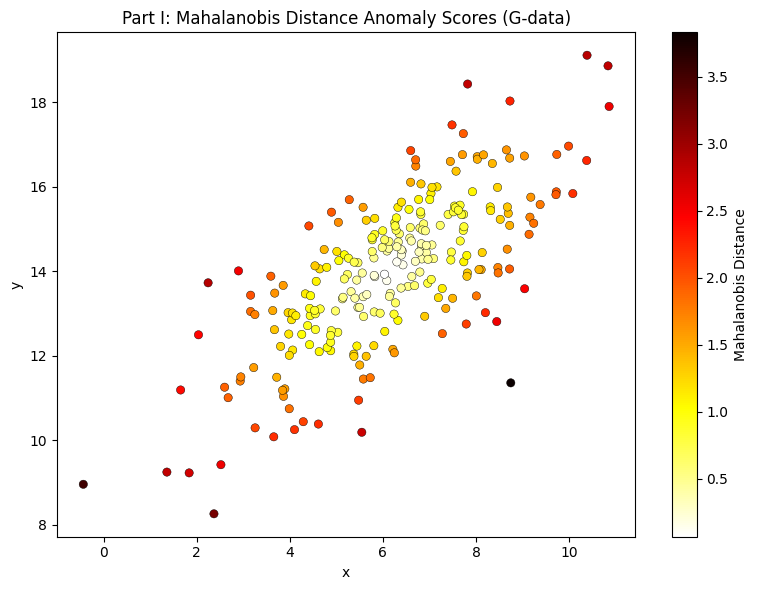

Top 5 Anomalies (Mahalanobis):
             x          y     mahal
41    8.747885  11.359886  3.831225
8    -0.438606   8.958312  3.528900
26    2.368932   8.259790  3.225480
67    2.243288  13.728437  2.862487
204  10.386685  19.115480  2.856695


In [4]:
mean = gdata[['x', 'y']].mean().values
cov_matrix = np.cov(gdata['x'], gdata['y'])
cov_inv = np.linalg.inv(cov_matrix)

mahal_scores = []

for i in range(len(gdata)):
    row = gdata.iloc[i]
    score = mahalanobis([row['x'], row['y']], mean, cov_inv)
    mahal_scores.append(score)

gdata['mahal'] = mahal_scores

# Scatter plot
plt.figure(figsize=(8, 6))
sc = plt.scatter(gdata['x'], gdata['y'], c=gdata['mahal'], cmap='hot_r', edgecolors='k', linewidths=0.3)
plt.colorbar(sc, label='Mahalanobis Distance')
plt.title('Part I: Mahalanobis Distance Anomaly Scores (G-data)')
plt.xlabel('x')
plt.ylabel('y')
plt.tight_layout()
plt.show()

# Top 5 anomalies
top5 = gdata.nlargest(5, 'mahal')
print("Top 5 Anomalies (Mahalanobis):")
print(top5[['x', 'y', 'mahal']].to_string(index=True))

## Part II

#### Compound Dataset


Top 5 Anomalies (compound, k=1):
  Index 43: (38.8500, 22.4000), score=2.4418
  Index 22: (34.7000, 8.5500), score=2.4005
  Index 21: (31.9500, 8.6000), score=2.3265
  Index 13: (27.2500, 11.9500), score=2.2023
  Index 36: (42.9000, 11.2500), score=2.1840

Top 5 Anomalies (compound, k=2):
  Index 0: (26.7500, 22.1500), score=3.0500
  Index 42: (42.2500, 22.1500), score=2.7166
  Index 36: (42.9000, 11.2500), score=2.6912
  Index 22: (34.7000, 8.5500), score=2.6707
  Index 43: (38.8500, 22.4000), score=2.5080

Top 5 Anomalies (compound, k=5):
  Index 19: (27.1500, 7.8500), score=4.7885
  Index 42: (42.2500, 22.1500), score=4.4096
  Index 37: (41.9500, 8.5000), score=4.3012
  Index 0: (26.7500, 22.1500), score=4.2154
  Index 40: (42.5500, 19.4500), score=4.1863


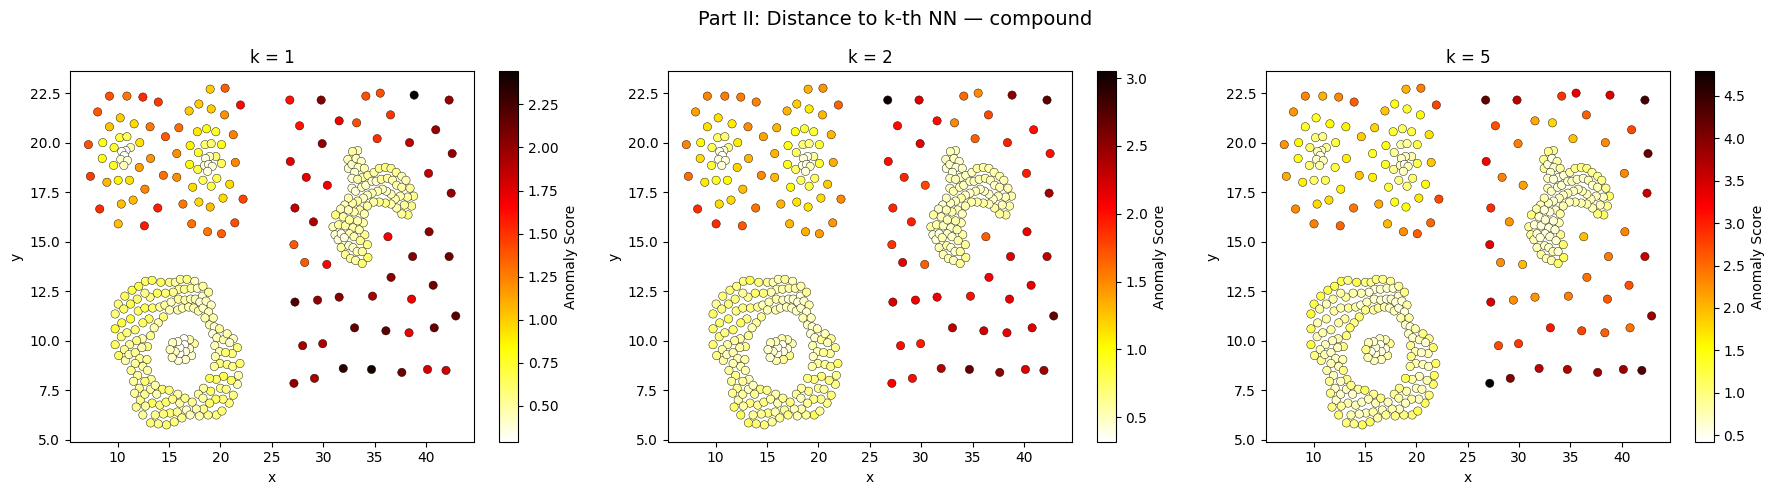

In [5]:
k_values = [1, 2, 5]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Part II: Distance to k-th NN — compound', fontsize=14)
for i, k in enumerate(k_values):
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(compound[['x', 'y']])
    distances, _ = nn.kneighbors(compound[['x', 'y']])
    anomaly_score = distances[:, k]
    ax = axes[i]
    sc = ax.scatter(compound['x'], compound['y'], c=anomaly_score, cmap='hot_r', edgecolors='k', linewidths=0.3)
    fig.colorbar(sc, ax=ax, label='Anomaly Score')
    ax.set_title(f'k = {k}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    top5_idx = np.argsort(anomaly_score)[-5:][::-1]
    print(f"\nTop 5 Anomalies (compound, k={k}):")
    for idx in top5_idx:
        print(f"  Index {idx}: ({compound.iloc[idx]['x']:.4f}, {compound.iloc[idx]['y']:.4f}), score={anomaly_score[idx]:.4f}")
plt.tight_layout()
plt.show()

#### Flame Dataset



Top 5 Anomalies (flame, k=1):
  Index 0: (1.8500, 27.8000), score=1.2540
  Index 1: (1.3500, 26.6500), score=1.2540
  Index 204: (10.5500, 25.6000), score=0.9192
  Index 192: (10.3500, 24.1000), score=0.9179
  Index 201: (8.3500, 27.3500), score=0.9124

Top 5 Anomalies (flame, k=2):
  Index 0: (1.8500, 27.8000), score=2.7613
  Index 1: (1.3500, 26.6500), score=2.6443
  Index 204: (10.5500, 25.6000), score=1.0817
  Index 168: (4.6500, 22.5500), score=1.0548
  Index 163: (5.2000, 21.1000), score=1.0308

Top 5 Anomalies (flame, k=5):
  Index 0: (1.8500, 27.8000), score=3.5584
  Index 1: (1.3500, 26.6500), score=3.4004
  Index 197: (4.5500, 26.6500), score=1.5532
  Index 196: (3.9000, 25.9500), score=1.5508
  Index 204: (10.5500, 25.6000), score=1.5133


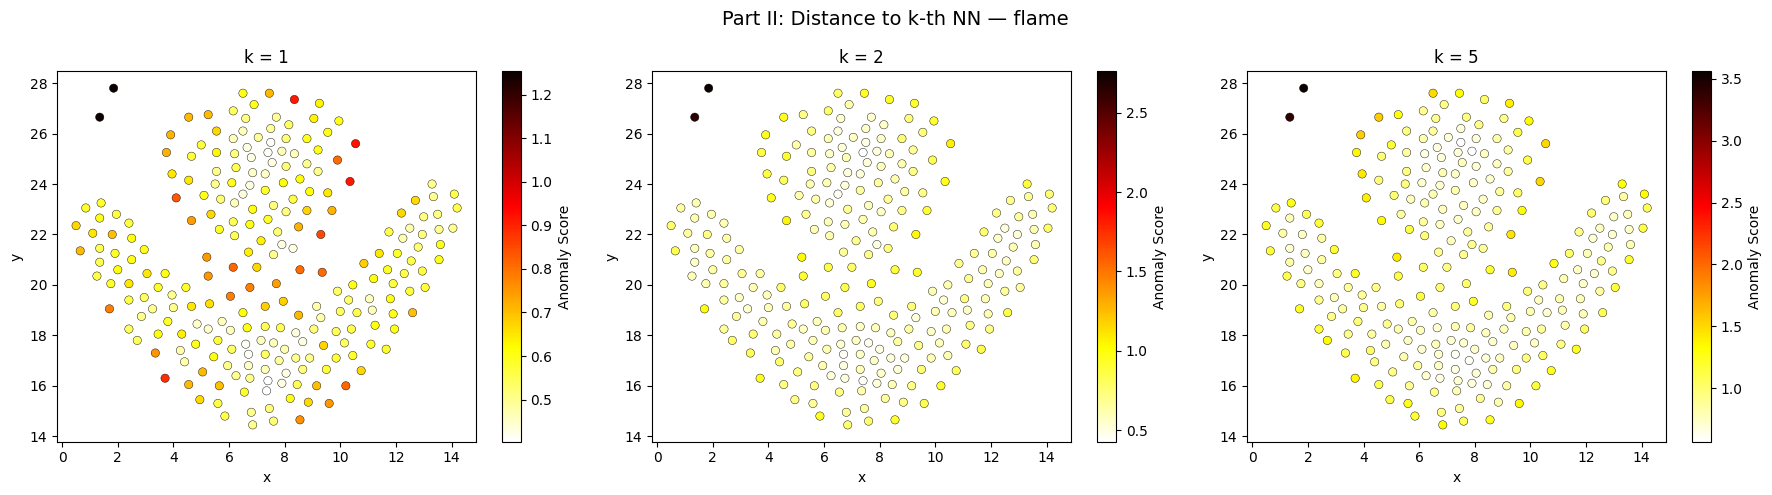

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Part II: Distance to k-th NN — flame', fontsize=14)
for i, k in enumerate(k_values):
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(flame[['x', 'y']])
    distances, _ = nn.kneighbors(flame[['x', 'y']])
    anomaly_score = distances[:, k]
    ax = axes[i]
    sc = ax.scatter(flame['x'], flame['y'], c=anomaly_score, cmap='hot_r', edgecolors='k', linewidths=0.3)
    fig.colorbar(sc, ax=ax, label='Anomaly Score')
    ax.set_title(f'k = {k}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    top5_idx = np.argsort(anomaly_score)[-5:][::-1]
    print(f"\nTop 5 Anomalies (flame, k={k}):")
    for idx in top5_idx:
        print(f"  Index {idx}: ({flame.iloc[idx]['x']:.4f}, {flame.iloc[idx]['y']:.4f}), score={anomaly_score[idx]:.4f}")
plt.tight_layout()
plt.show()

#### Pathbased dataset


Top 5 Anomalies (pathbased, k=1):
  Index 202: (12.4500, 9.1500), score=2.5164
  Index 203: (10.1000, 10.0500), score=2.4135
  Index 270: (10.3000, 22.7500), score=2.2771
  Index 266: (7.4500, 19.0000), score=1.7205
  Index 106: (29.1500, 16.5000), score=1.5338

Top 5 Anomalies (pathbased, k=2):
  Index 202: (12.4500, 9.1500), score=3.0017
  Index 203: (10.1000, 10.0500), score=2.5164
  Index 270: (10.3000, 22.7500), score=2.3265
  Index 294: (17.9000, 15.6000), score=2.1360
  Index 197: (19.9500, 19.8000), score=2.0555

Top 5 Anomalies (pathbased, k=5):
  Index 202: (12.4500, 9.1500), score=3.4154
  Index 270: (10.3000, 22.7500), score=3.2442
  Index 0: (11.2500, 5.0500), score=3.0270
  Index 1: (10.9500, 4.7000), score=2.9833
  Index 102: (25.5000, 4.1000), score=2.9741


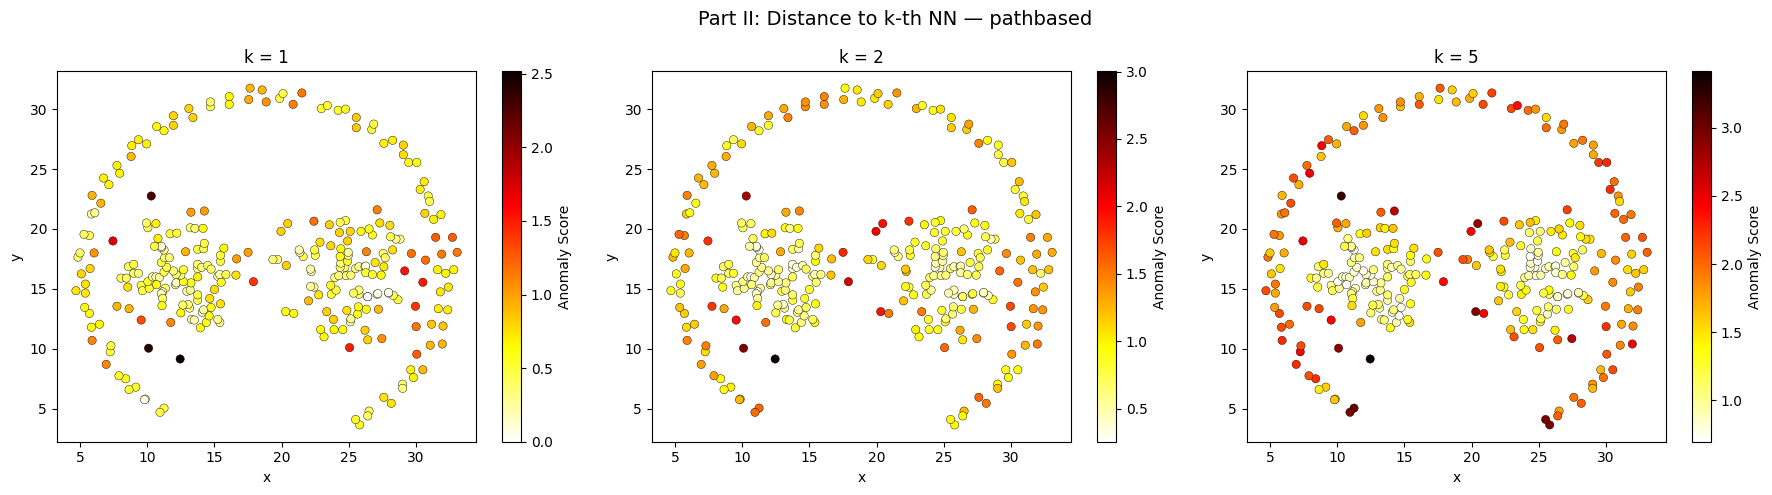

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Part II: Distance to k-th NN — pathbased', fontsize=14)
for i, k in enumerate(k_values):
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(pathbased[['x', 'y']])
    distances, _ = nn.kneighbors(pathbased[['x', 'y']])
    anomaly_score = distances[:, k]
    ax = axes[i]
    sc = ax.scatter(pathbased['x'], pathbased['y'], c=anomaly_score, cmap='hot_r', edgecolors='k', linewidths=0.3)
    fig.colorbar(sc, ax=ax, label='Anomaly Score')
    ax.set_title(f'k = {k}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    top5_idx = np.argsort(anomaly_score)[-5:][::-1]
    print(f"\nTop 5 Anomalies (pathbased, k={k}):")
    for idx in top5_idx:
        print(f"  Index {idx}: ({pathbased.iloc[idx]['x']:.4f}, {pathbased.iloc[idx]['y']:.4f}), score={anomaly_score[idx]:.4f}")
plt.tight_layout()
plt.show()

## Part III

Method 1: Density = 1 / (distance to k-th neighbor)

Top 5 Anomalies (compound, k=1, method=1/kth_dist):
  Index 9: (29.0500, 16.0000), score=4.2851
  Index 44: (38.4000, 20.0000), score=4.1548
  Index 24: (36.3000, 15.2500), score=3.5553
  Index 39: (40.2500, 18.4500), score=3.4819
  Index 46: (33.2500, 21.0000), score=3.2855

Top 5 Anomalies (compound, k=2, method=1/kth_dist):
  Index 39: (40.2500, 18.4500), score=3.6449
  Index 44: (38.4000, 20.0000), score=3.5738
  Index 12: (30.3500, 13.8500), score=3.5287
  Index 7: (30.4000, 17.8500), score=3.3924
  Index 23: (34.8000, 12.2500), score=3.1943

Top 5 Anomalies (compound, k=5, method=1/kth_dist):
  Index 44: (38.4000, 20.0000), score=2.4608
  Index 12: (30.3500, 13.8500), score=2.4293
  Index 24: (36.3000, 15.2500), score=2.3715
  Index 7: (30.4000, 17.8500), score=2.2517
  Index 39: (40.2500, 18.4500), score=2.1189


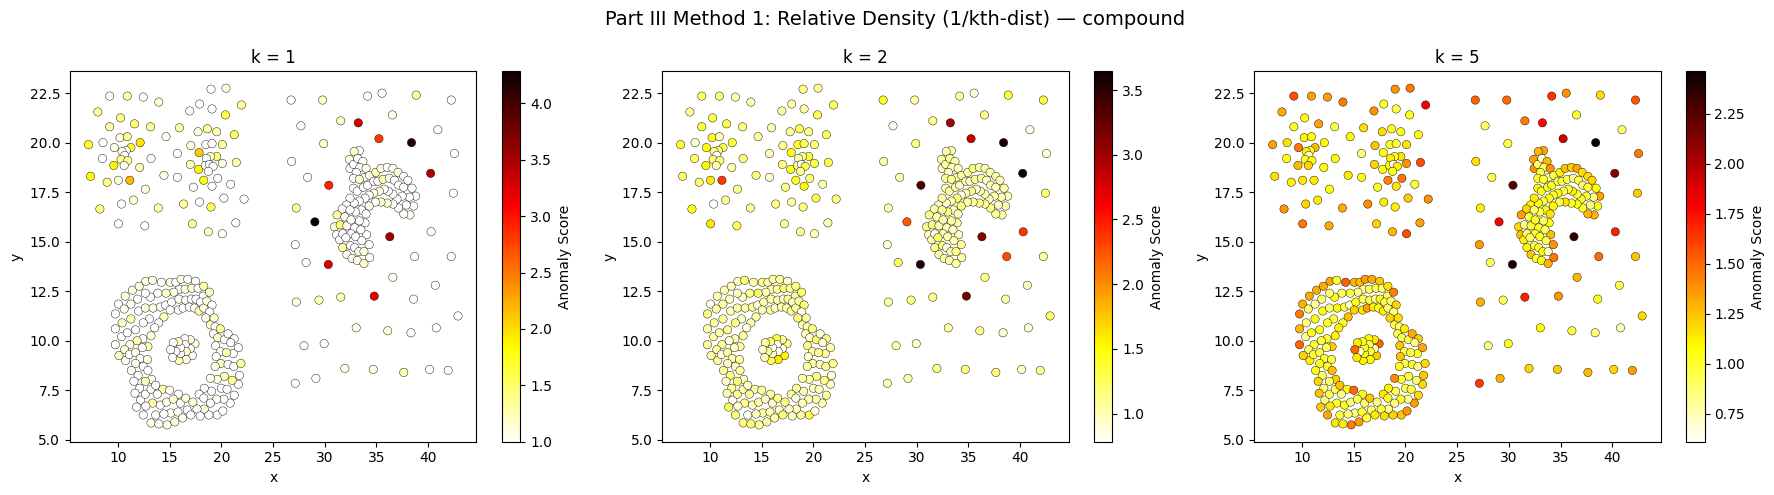


Top 5 Anomalies (flame, k=1, method=1/kth_dist):
  Index 105: (8.5000, 18.8000), score=1.6440
  Index 225: (5.5500, 26.1000), score=1.4552
  Index 201: (8.3500, 27.3500), score=1.4427
  Index 139: (12.2000, 22.8500), score=1.4221
  Index 192: (10.3500, 24.1000), score=1.4080

Top 5 Anomalies (flame, k=2, method=1/kth_dist):
  Index 0: (1.8500, 27.8000), score=1.9675
  Index 1: (1.3500, 26.6500), score=1.8629
  Index 20: (1.7000, 19.0500), score=1.5988
  Index 55: (5.8500, 14.8000), score=1.4418
  Index 223: (4.6500, 25.1000), score=1.4280

Top 5 Anomalies (flame, k=5, method=1/kth_dist):
  Index 0: (1.8500, 27.8000), score=2.1935
  Index 1: (1.3500, 26.6500), score=2.1018
  Index 199: (6.5000, 27.6000), score=1.5458
  Index 174: (9.3000, 22.0000), score=1.5220
  Index 192: (10.3500, 24.1000), score=1.4961


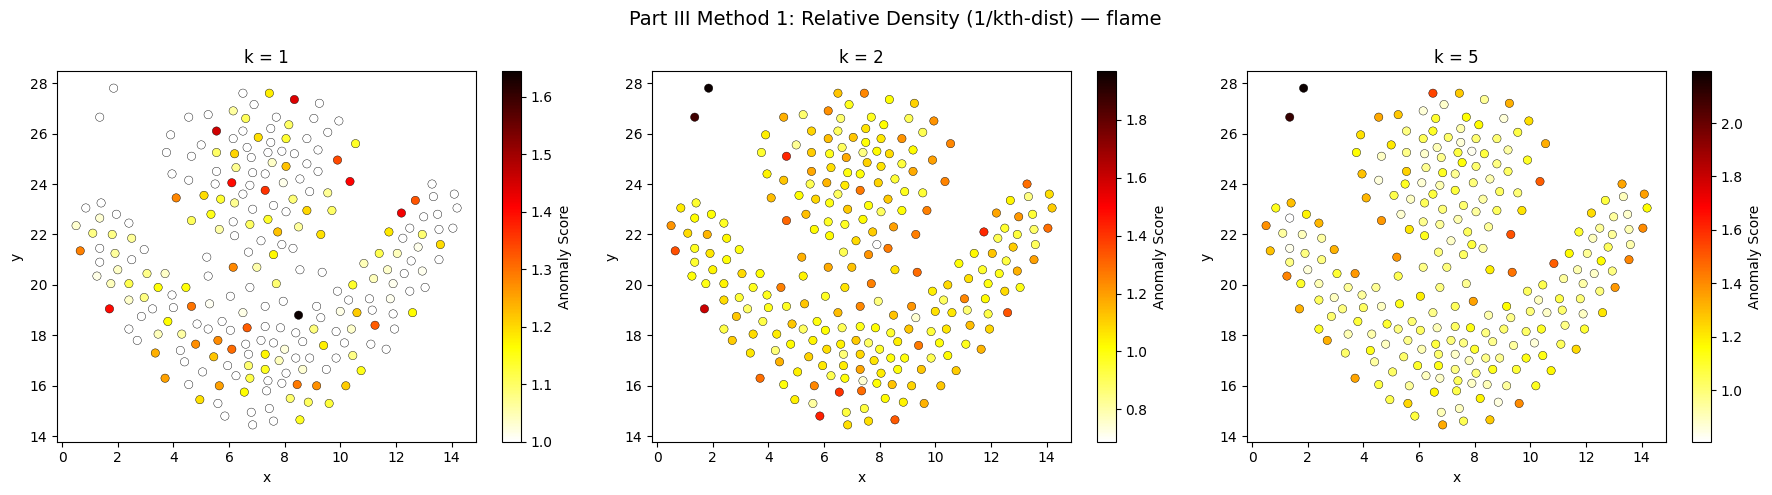


Top 5 Anomalies (pathbased, k=1, method=1/kth_dist):
  Index 116: (28.3000, 14.4500), score=8.0623
  Index 157: (26.2500, 16.3500), score=7.1063
  Index 265: (10.8000, 19.2000), score=6.9642
  Index 270: (10.3000, 22.7500), score=5.5227
  Index 264: (10.5500, 18.5500), score=5.0000

Top 5 Anomalies (pathbased, k=2, method=1/kth_dist):
  Index 270: (10.3000, 22.7500), score=3.3151
  Index 294: (17.9000, 15.6000), score=2.6161
  Index 202: (12.4500, 9.1500), score=2.4948
  Index 293: (16.6000, 16.1500), score=2.3055
  Index 197: (19.9500, 19.8000), score=2.1647

Top 5 Anomalies (pathbased, k=5, method=1/kth_dist):
  Index 202: (12.4500, 9.1500), score=2.4760
  Index 144: (20.3000, 13.1000), score=1.9393
  Index 111: (27.4500, 10.8500), score=1.8179
  Index 0: (11.2500, 5.0500), score=1.7654
  Index 1: (10.9500, 4.7000), score=1.7371


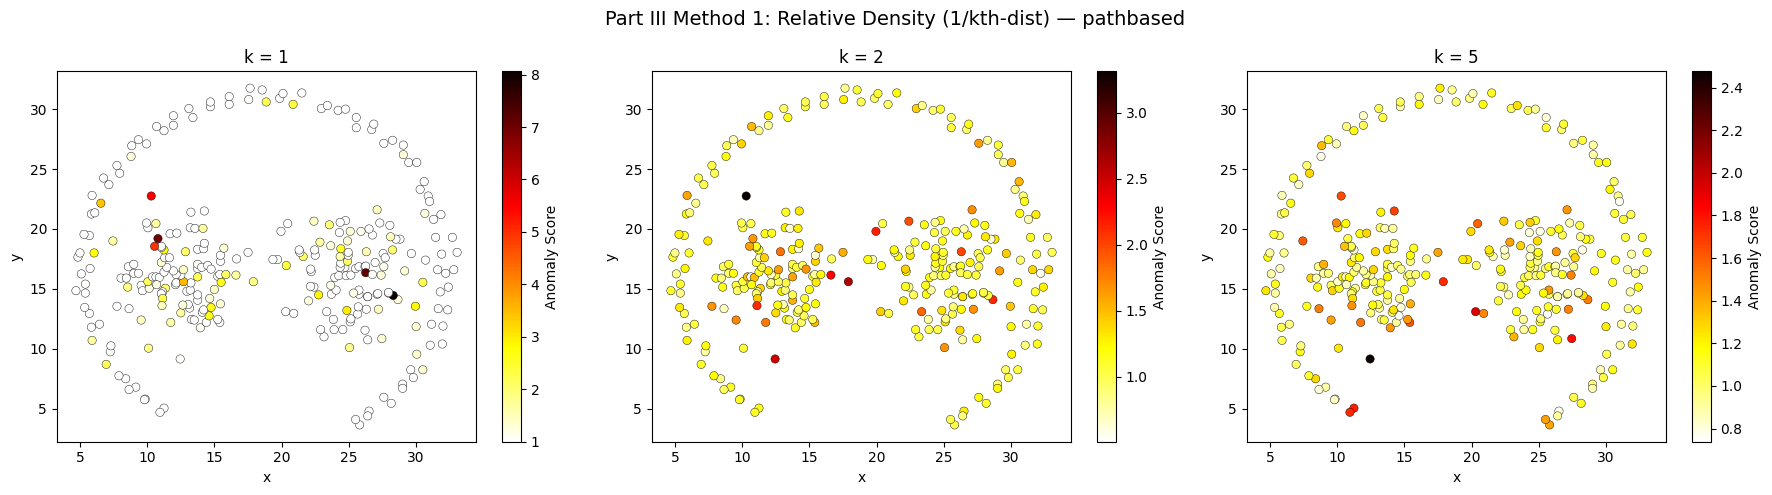

Method 2: Density = 1 / (avg distance to k neighbors)

Top 5 Anomalies (compound, k=1, method=1/avg_dist):
  Index 9: (29.0500, 16.0000), score=4.2851
  Index 44: (38.4000, 20.0000), score=4.1548
  Index 24: (36.3000, 15.2500), score=3.5553
  Index 39: (40.2500, 18.4500), score=3.4819
  Index 46: (33.2500, 21.0000), score=3.2855

Top 5 Anomalies (compound, k=2, method=1/avg_dist):
  Index 44: (38.4000, 20.0000), score=3.8366
  Index 12: (30.3500, 13.8500), score=3.6279
  Index 39: (40.2500, 18.4500), score=3.5922
  Index 7: (30.4000, 17.8500), score=3.3751
  Index 24: (36.3000, 15.2500), score=3.3155

Top 5 Anomalies (compound, k=5, method=1/avg_dist):
  Index 44: (38.4000, 20.0000), score=3.1433
  Index 12: (30.3500, 13.8500), score=2.9066
  Index 24: (36.3000, 15.2500), score=2.7432
  Index 7: (30.4000, 17.8500), score=2.7159
  Index 39: (40.2500, 18.4500), score=2.6705


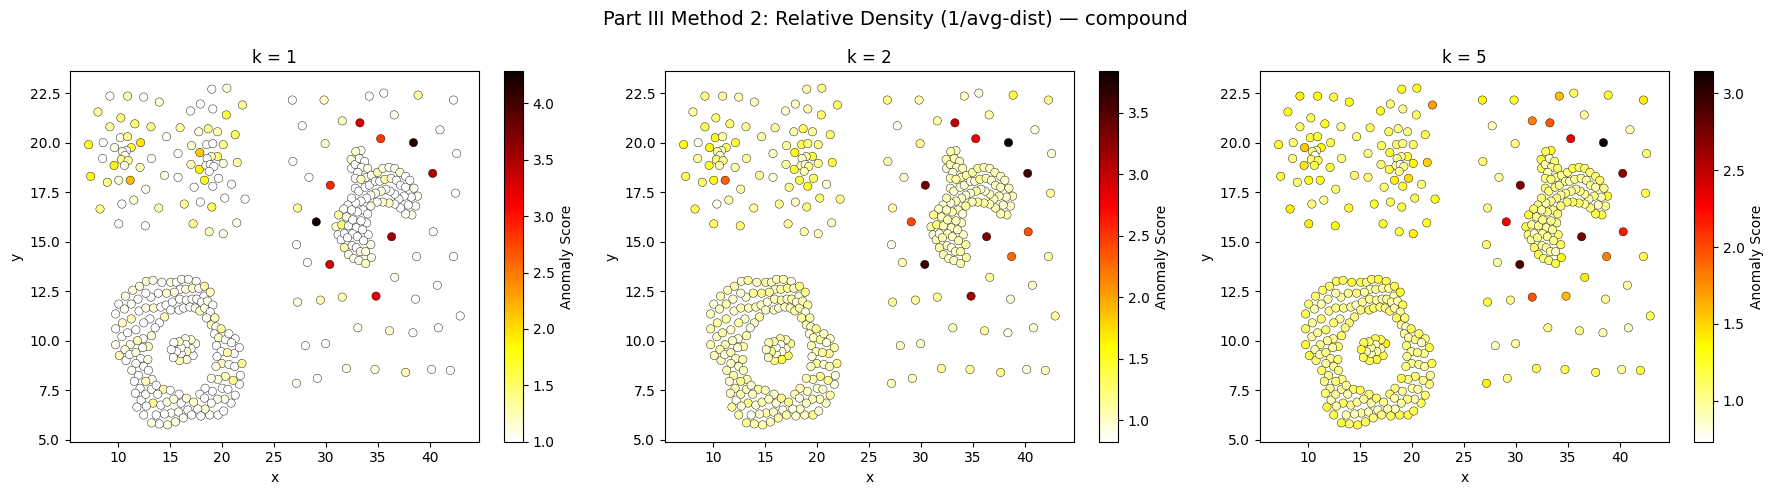


Top 5 Anomalies (flame, k=1, method=1/avg_dist):
  Index 105: (8.5000, 18.8000), score=1.6440
  Index 225: (5.5500, 26.1000), score=1.4552
  Index 201: (8.3500, 27.3500), score=1.4427
  Index 139: (12.2000, 22.8500), score=1.4221
  Index 192: (10.3500, 24.1000), score=1.4080

Top 5 Anomalies (flame, k=2, method=1/avg_dist):
  Index 0: (1.8500, 27.8000), score=1.7164
  Index 1: (1.3500, 26.6500), score=1.6518
  Index 20: (1.7000, 19.0500), score=1.4890
  Index 40: (3.7000, 16.3000), score=1.3885
  Index 132: (11.7500, 22.1000), score=1.3132

Top 5 Anomalies (flame, k=5, method=1/avg_dist):
  Index 0: (1.8500, 27.8000), score=2.2894
  Index 1: (1.3500, 26.6500), score=2.2717
  Index 174: (9.3000, 22.0000), score=1.4402
  Index 158: (9.3500, 20.5000), score=1.4234
  Index 192: (10.3500, 24.1000), score=1.4196


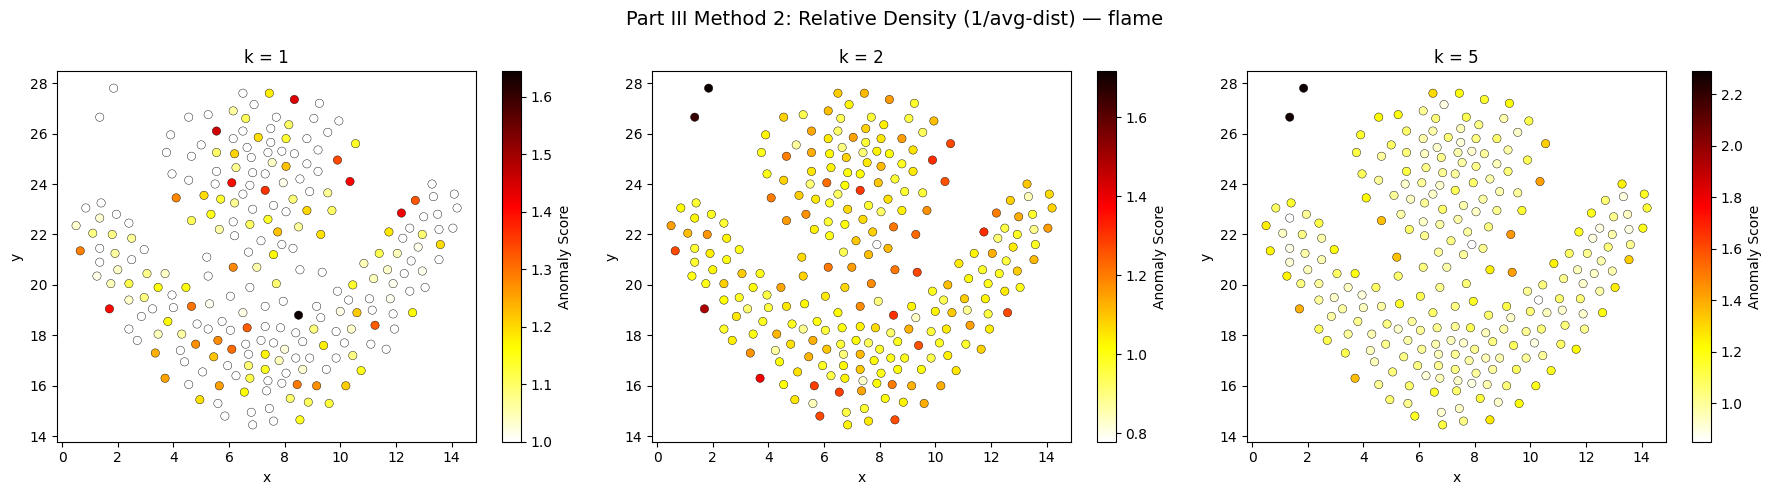


Top 5 Anomalies (pathbased, k=1, method=1/avg_dist):
  Index 116: (28.3000, 14.4500), score=8.0623
  Index 157: (26.2500, 16.3500), score=7.1063
  Index 265: (10.8000, 19.2000), score=6.9642
  Index 270: (10.3000, 22.7500), score=5.5227
  Index 264: (10.5500, 18.5500), score=5.0000

Top 5 Anomalies (pathbased, k=2, method=1/avg_dist):
  Index 270: (10.3000, 22.7500), score=3.7144
  Index 162: (26.3000, 18.1000), score=2.7866
  Index 294: (17.9000, 15.6000), score=2.5685
  Index 202: (12.4500, 9.1500), score=2.4932
  Index 264: (10.5500, 18.5500), score=2.4153

Top 5 Anomalies (pathbased, k=5, method=1/avg_dist):
  Index 202: (12.4500, 9.1500), score=2.8257
  Index 270: (10.3000, 22.7500), score=2.0957
  Index 294: (17.9000, 15.6000), score=2.0781
  Index 144: (20.3000, 13.1000), score=1.9492
  Index 162: (26.3000, 18.1000), score=1.8977


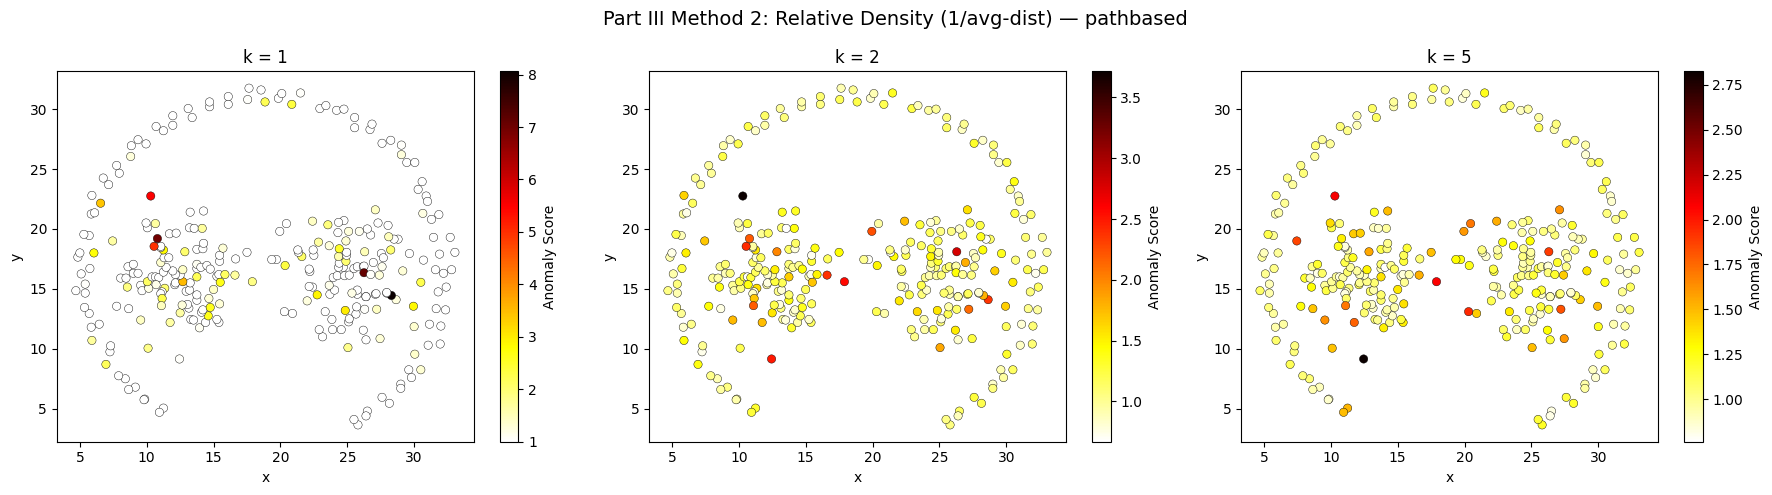

In [10]:
datasets = {'compound': compound, 'flame': flame, 'pathbased': pathbased}
def relative_density_kth(df, k):
    # Density = 1 / distance_to_kth_neighbor. Anomaly = avg_density_of_neighbors / point_density
    coords = df[['x', 'y']].values
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(coords)
    distances, indices = nn.kneighbors(coords)

    kth_dist = distances[:, k]
    density = 1.0 / (kth_dist + 1e-10)  # avoid division by zero

    anomaly_scores = np.zeros(len(df))
    for i in range(len(df)):
        neighbor_indices = indices[i, 1:]  # exclude self
        avg_neighbor_density = np.mean(density[neighbor_indices])
        anomaly_scores[i] = avg_neighbor_density / (density[i] + 1e-10)

    return anomaly_scores


def relative_density_avg(df, k):
    # Density = 1 / avg_distance_to_k_neighbors. Anomaly = avg_density_of_neighbors / point_density
    coords = df[['x', 'y']].values
    nn = NearestNeighbors(n_neighbors=k + 1)
    nn.fit(coords)
    distances, indices = nn.kneighbors(coords)

    avg_dist = np.mean(distances[:, 1:], axis=1)  # average of k neighbor distances
    density = 1.0 / (avg_dist + 1e-10)

    anomaly_scores = np.zeros(len(df))
    for i in range(len(df)):
        neighbor_indices = indices[i, 1:]
        avg_neighbor_density = np.mean(density[neighbor_indices])
        anomaly_scores[i] = avg_neighbor_density / (density[i] + 1e-10)

    return anomaly_scores


# Method 1: density = 1 / dist to k-th neighbor
print("Method 1: Density = 1 / (distance to k-th neighbor)")

for name, df in datasets.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Part III Method 1: Relative Density (1/kth-dist) — {name}', fontsize=14)
    for i, k in enumerate(k_values):
        scores = relative_density_kth(df, k)
        ax = axes[i]
        sc = ax.scatter(df['x'], df['y'], c=scores, cmap='hot_r', edgecolors='k', linewidths=0.3)
        fig.colorbar(sc, ax=ax, label='Anomaly Score')
        ax.set_title(f'k = {k}')
        ax.set_xlabel('x')
        ax.set_ylabel('y')

        top5_idx = np.argsort(scores)[-5:][::-1]
        print(f"\nTop 5 Anomalies ({name}, k={k}, method=1/kth_dist):")
        for idx in top5_idx:
            print(f"  Index {idx}: ({df.iloc[idx]['x']:.4f}, {df.iloc[idx]['y']:.4f}), score={scores[idx]:.4f}")

    plt.tight_layout()
    plt.show()

# Method 2: density = 1 / avg distance to k neighbors
print("Method 2: Density = 1 / (avg distance to k neighbors)")

for name, df in datasets.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Part III Method 2: Relative Density (1/avg-dist) — {name}', fontsize=14)
    for i, k in enumerate(k_values):
        scores = relative_density_avg(df, k)
        ax = axes[i]
        sc = ax.scatter(df['x'], df['y'], c=scores, cmap='hot_r', edgecolors='k', linewidths=0.3)
        fig.colorbar(sc, ax=ax, label='Anomaly Score')
        ax.set_title(f'k = {k}')
        ax.set_xlabel('x')
        ax.set_ylabel('y')

        top5_idx = np.argsort(scores)[-5:][::-1]
        print(f"\nTop 5 Anomalies ({name}, k={k}, method=1/avg_dist):")
        for idx in top5_idx:
            print(f"  Index {idx}: ({df.iloc[idx]['x']:.4f}, {df.iloc[idx]['y']:.4f}), score={scores[idx]:.4f}")

    plt.tight_layout()
    plt.show()